# Hands-on 8: Deteksi Anomali Dasar dengan Aturan Statistik

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 4.

Tiga metode: aturan domain (suhu > 35 C, CO2 > 1200 ppm, daya > 250 W), Z-score (|z| > 3),
dan IQR (batas Q1 - 1.5 IQR s.d. Q3 + 1.5 IQR). Titik yang muncul di ketiga metode
layak diperiksa lebih serius.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Bangkitkan Dataset dengan Anomali Suntikan

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/generate_anomaly_dataset.py"], capture_output=True, text=True)
print(r.stdout)

[SUKSES] Dataset anomali tersimpan: data/raw/room_sensor_anomaly.csv (144 baris)
[INFO] Titik anomali disuntikkan pada: ['2026-01-01 09:30:00', '2026-01-01 13:00:00', '2026-01-01 15:20:00']



## 2. Metode 1 - Aturan Domain

In [3]:
r = subprocess.run([sys.executable, "scripts/detect_anomaly_rules.py"], capture_output=True, text=True)
print(r.stdout[-1500:])

         26.30      443       86.38         False
2026-01-01 21:10:00          25.95      437       88.62         False
2026-01-01 21:20:00          25.63      449       89.89         False
2026-01-01 21:30:00          25.79      453       95.40         False
2026-01-01 21:40:00          25.47      449       94.56         False
2026-01-01 21:50:00          25.38      455       90.17         False
2026-01-01 22:00:00          25.23      447       89.69         False
2026-01-01 22:10:00          25.28      439       95.08         False
2026-01-01 22:20:00          24.98      455       92.83         False
2026-01-01 22:30:00          24.89      463       89.36         False
2026-01-01 22:40:00          24.54      439       94.76         False
2026-01-01 22:50:00          24.53      450       91.28         False
2026-01-01 23:00:00          24.37      462       92.57         False
2026-01-01 23:10:00          24.50      448       86.28         False
2026-01-01 23:20:00          24.31      

## 3. Metode 2 - Z-Score

In [4]:
r = subprocess.run([sys.executable, "scripts/detect_anomaly_zscore.py"], capture_output=True, text=True)
print(r.stdout)

=== Deteksi anomali - Z-score (|z| > 3) ===
          timestamp  temperature_c   z_temp  co2_ppm    z_co2  power_watt  z_power
2026-01-01 09:30:00          45.00 7.083354     1500 4.616784      300.00 5.477394
2026-01-01 13:00:00          28.53 0.897352     1600 5.126757      160.34 1.384898
2026-01-01 15:20:00          29.07 1.100172      794 1.016370      320.00 6.063460

[INFO] Titik anomali terdeteksi: 3



## 4. Metode 3 - IQR

In [5]:
r = subprocess.run([sys.executable, "scripts/detect_anomaly_iqr.py"], capture_output=True, text=True)
print(r.stdout)

[INFO] Batas IQR:
  temperature_c: [17.33, 34.70]
  co2_ppm      : [-0.88, 1206.12]
  power_watt   : [19.95, 205.90]

=== Deteksi anomali - IQR ===
          timestamp  temperature_c  co2_ppm  power_watt
2026-01-01 09:30:00          45.00     1500      300.00
2026-01-01 13:00:00          28.53     1600      160.34
2026-01-01 15:20:00          29.07      794      320.00

[INFO] Titik anomali terdeteksi: 3



## 5. Versi Gabungan dan Visualisasi

In [6]:
r = subprocess.run([sys.executable, "scripts/detect_anomaly_all.py"], capture_output=True, text=True)
print(r.stdout)
r = subprocess.run([sys.executable, "scripts/plot_anomaly.py"], capture_output=True, text=True)
print(r.stdout)

=== Titik yang terdeteksi minimal satu metode ===
          timestamp  temperature_c  co2_ppm  power_watt  anomaly_rule  anomaly_zscore  anomaly_iqr  anomaly_all_methods
2026-01-01 09:30:00          45.00     1500      300.00          True            True         True                 True
2026-01-01 13:00:00          28.53     1600      160.34          True            True         True                 True
2026-01-01 15:20:00          29.07      794      320.00          True            True         True                 True

[INFO] rule: 3 titik
[INFO] zscore: 3 titik
[INFO] iqr: 3 titik
[INFO] ketiga metode sekaligus: 3 titik
[SUKSES] Hasil lengkap disimpan ke data/processed/room_sensor_anomaly_flags.csv



[SUKSES] outputs/figures/anomali_suhu.png
[SUKSES] outputs/figures/anomali_co2.png
[SUKSES] outputs/figures/anomali_daya.png



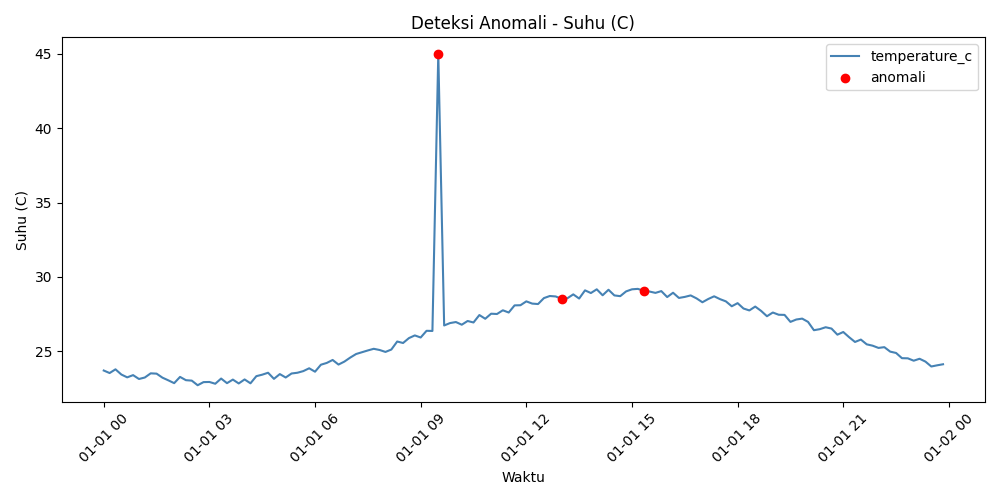

In [7]:
from IPython.display import Image
Image("outputs/figures/anomali_suhu.png")

## Penutup

Ketiga metode sepakat pada 3 titik anomali suntikan (09:30 lonjakan gabungan, 13:00 CO2,
15:20 daya). Hasil lengkap tersimpan di `data/processed/room_sensor_anomaly_flags.csv`.

## Figur persis sesuai buku (Hands-on 8)

`scripts/book_figures.py --only anomaly` membuat `outputs/figures/anomaly_temperature_rule.png` dengan judul, label sumbu, dan ukuran sesuai listing buku.

[SUKSES] figur 'anomaly' dibuat di outputs/figures
 


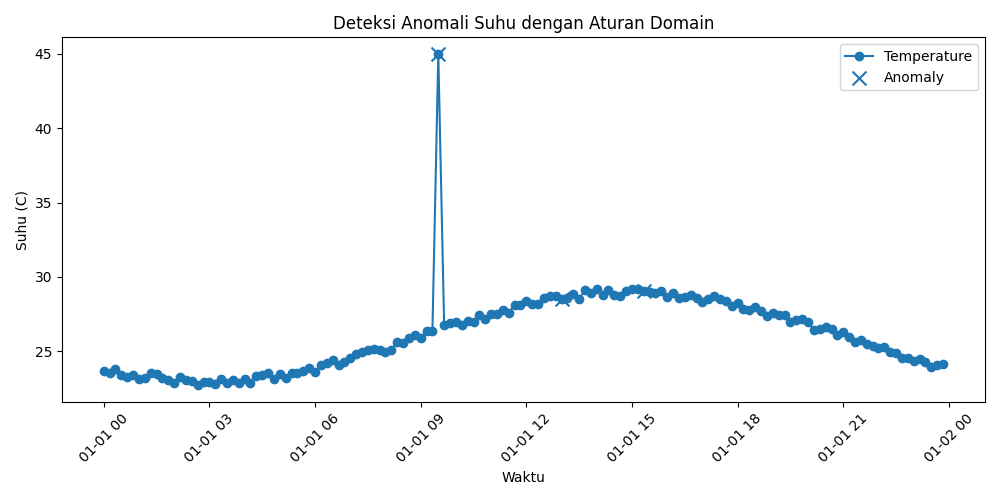

In [8]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/book_figures.py", "--only", "anomaly"], capture_output=True, text=True)
print(r.stdout, r.stderr)
from IPython.display import Image, display
display(Image("outputs/figures/anomaly_temperature_rule.png"))

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 8 dalam urutan buku) agar dapat dijadikan panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 10. Langkah kerja yang harus dilakukan pembaca

Tahap

Aktivitas

Tujuan

Baca dataset.

Memuat data agar siap diperiksa, dibersihkan, dan
dianalisis lebih lanjut.

Tentukan ambang
domain.

Menetapkan batas normal berdasarkan pengetahuan
proses, konteks operasional, atau aturan bisnis.

Tandai anomali
berbasis aturan.

Mengidentifikasi data yang melampaui ambang domain
sebagai indikasi awal anomali.

Hitung Z-score.

Mengukur seberapa jauh suatu nilai menyimpang dari
rata-rata dalam satuan simpangan baku.

Hitung batas IQR.

Menentukan outlier berdasarkan sebaran data
menggunakan kuartil dan interquartile range.

Bandingkan hasil
ketiga metode.

Melihat konsistensi dan perbedaan temuan antara aturan
domain, Z-score, dan IQR.

Buat visualisasi.

Menampilkan pola, penyimpangan, dan titik anomali agar
lebih mudah dipahami secara visual.

Tulis interpretasi
operasional.

Menjelaskan makna anomali bagi proses nyata serta
kemungkinan tindak lanjut yang perlu dilakukan.